In [1]:
%load_ext autoreload
%autoreload 2

import os, sys
dir1 = os.path.dirname(os.path.abspath('..'))
if not dir1 in sys.path: sys.path.append(dir1)

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import yaml
import seaborn as sns
from utils.plots import *
from utils.figures import cmap

from scipy.stats import ks_2samp
from scipy.stats import linregress

from utils.figures import plot_metrics
from matplotlib.gridspec import GridSpec


FIG = 'fig_ablations'

config_fpath = Path(f'{FIG}.yml')
data_fpath = Path(f'{FIG}_df.csv')

with open(config_fpath, 'r') as f:
    config = yaml.safe_load(f)
df = pd.read_csv(data_fpath)


In [3]:
def subfigure_x(y,  sub='x)', ylim=None, yticks=None, yticklabels=None, debug=False,
                hidexticks=False):
    title = y['name']
    metric = y['metric']
    methods = [x['method'] for x in y['x']]
    names = [x['name'] for x in y['x']]
    log = y.get('log', False)

    df_exp = df[df['exp']==y['experiment']]
    df_temp = plot_metrics(df_exp, metric, methods, names, log=log)

    plt.gca().set_xmargin(0.05)

    plt.gca().tick_params(axis="x", direction="in", pad=-66)

    if not debug:
        plt.minorticks_off()
    plt.ylim(ylim)
    plt.yticks(yticks, yticklabels)
    
    plt.plot([np.nan], [np.nan], lw=0, label=title)
    lgnd = plt.legend(loc='lower right', bbox_to_anchor=(1, 1),
                      ncol=3, columnspacing=1.5,
                      frameon=False, borderpad=0.0, borderaxespad=0.1,
                      handlelength=1.5, handletextpad=0.5)
    for t in lgnd.get_texts():
        t.set_ha('right')

    sns.despine(ax=plt.gca(), bottom=(not debug), trim=True)
    labels = plt.gca().get_xticklabels()
    labels[1].set_weight('bold')

    if hidexticks:
        plt.xticks([], [])

    plt.title(sub, loc='left', pad=20, fontdict={'fontweight': 'bold'})


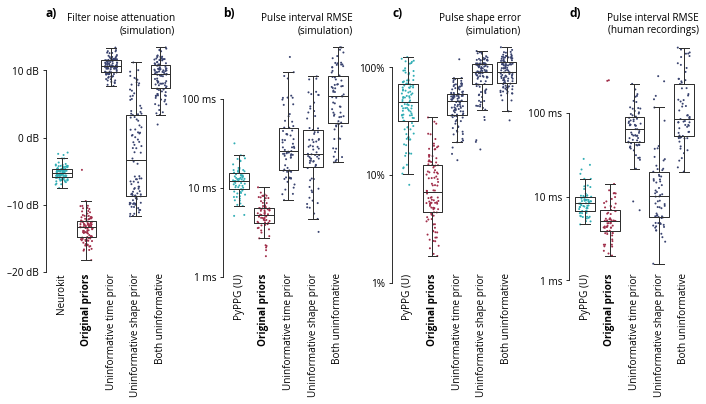

In [4]:
fig = plt.figure(figsize=(9.7,5.5), layout="constrained")
gs = GridSpec(1, 4, figure=fig, width_ratios=[1,1,1,1], wspace=0.03)

ylim = (-30, None)
yticks = [-20, -10, 0, 10]
yticklabels = ['–20 dB', '–10 dB', '0 dB', '10 dB']

fig.add_subplot(gs[0, 0])
subfigure_x(config['y'][0], 'a)', ylim, yticks, yticklabels)

ylim = (0.0002, None)
yticks = [0.001, 0.01, 0.1]
yticklabels = ['1 ms', '10 ms', '100 ms']

fig.add_subplot(gs[0, 1])
subfigure_x(config['y'][1], 'b)', ylim, yticks, yticklabels)
fig.add_subplot(gs[0, 3])
subfigure_x(config['y'][3], 'd)', ylim, yticks, yticklabels)

ylim = (0.003, None)
yticks = [0.01, 0.1, 1]
yticklabels = ['1%', '10%', '100%']

fig.add_subplot(gs[0, 2])
subfigure_x(config['y'][2], 'c)', ylim, yticks, yticklabels)

plt.savefig(f'{FIG}.pdf', transparent=True)
plt.savefig(f'{FIG}.png', transparent=True, dpi=200)
plt.show()
